In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn wordcloud sentence-transformers streamlit pdfplumber joblib

In [ ]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("resume_dataset_1200.csv")
print(df.shape)
df.info()
df.head()

(1200, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Name                    1200 non-null   object
 1   Age                     1200 non-null   int64 
 2   Gender                  1200 non-null   object
 3   Education_Level         1200 non-null   object
 4   Field_of_Study          1200 non-null   object
 5   Degrees                 1200 non-null   object
 6   Institute_Name          1200 non-null   object
 7   Graduation_Year         1200 non-null   int64 
 8   Experience_Years        1200 non-null   int64 
 9   Current_Job_Title       759 non-null    object
 10  Previous_Job_Titles     286 non-null    object
 11  Skills                  1200 non-null   object
 12  Certifications          881 non-null    object
 13  Target_Job_Description  1200 non-null   object
dtypes: int64(3), object(11)
memory usage: 131.4+ 

,Name,Age,Gender,Education_Level,Field_of_Study,Degrees,Institute_Name,Graduation_Year,Experience_Years,Current_Job_Title,Previous_Job_Titles,Skills,Certifications,Target_Job_Description
0,Akash Pillai,30,Non-Binary,Master's,Cybersecurity,Master's in Cybersecurity,University of Pennsylvania,2025,0,NaN,NaN,"Node.js, JavaScript, Deep Learning, Statistics...",Google Cloud Professional,Seeking a challenging role as a Software Devel...
1,Charlotte Taylor,27,Non-Binary,Bachelor's,Electronics Engineering,Bachelor's in Electronics Engineering,Pune University,2019,5,Cybersecurity Engineer,NaN,"Spark, Kubernetes, Terraform, Natural Language...",TensorFlow Developer Certificate,Targeting a Cybersecurity Engineer position to...
2,James Zhou,45,Male,Bachelor's,Computer Science,Bachelor's in Computer Science,Amity University,2023,2,Prompt Engineer,NaN,"Data Analysis, Node.js, Machine Learning, Linu...","Microsoft Azure Fundamentals, Cisco Certified ...",Targeting a Prompt Engineer position to utiliz...
3,Amelia Thomas,28,Male,Master's,Information Technology,Master's in Information Technology,University of Pennsylvania,2023,2,AI Engineer,NaN,"Docker, Kubernetes, Blockchain, Spark",NaN,Targeting a Data Scientist position where I ca...
4,Amanda Jain,42,Non-Binary,Master's,Electronics Engineering,Master's in Electronics Engineering,University of Toronto,2023,2,Cybersecurity Engineer,NaN,"Statistics, Blockchain, Kubernetes, Cybersecurity",NaN,Looking for an opportunity as a Prompt Enginee...


In [ ]:
for c in ["Current_Job_Title", "Previous_Job_Titles", "Certifications"]:
    df[c] = df[c].fillna("")

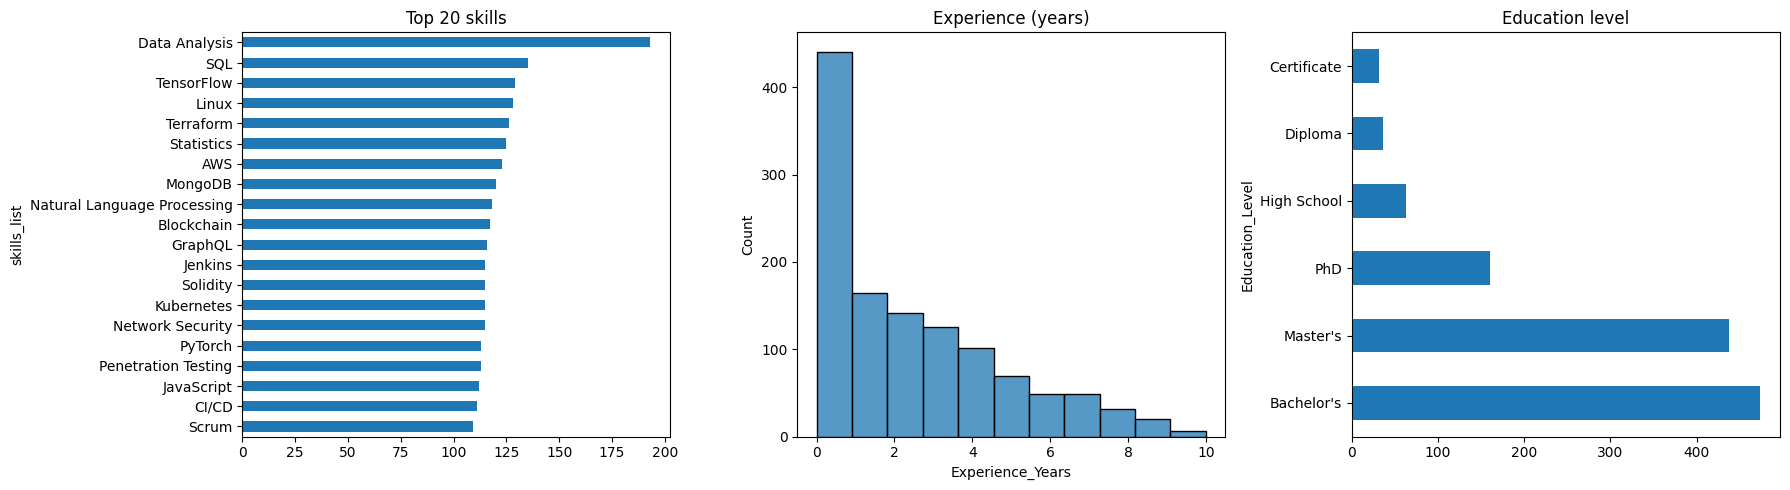

In [ ]:
df["skills_list"] = df["Skills"].apply(lambda s: [x.strip() for x in s.split(",")])
all_skills = df["skills_list"].explode()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
all_skills.value_counts().head(20).sort_values().plot.barh(ax=axes[0], title="Top 20 skills")
sns.histplot(df["Experience_Years"], bins=11, ax=axes[1]).set_title("Experience (years)")
df["Education_Level"].value_counts().plot.barh(ax=axes[2], title="Education level")
plt.tight_layout(); plt.show()

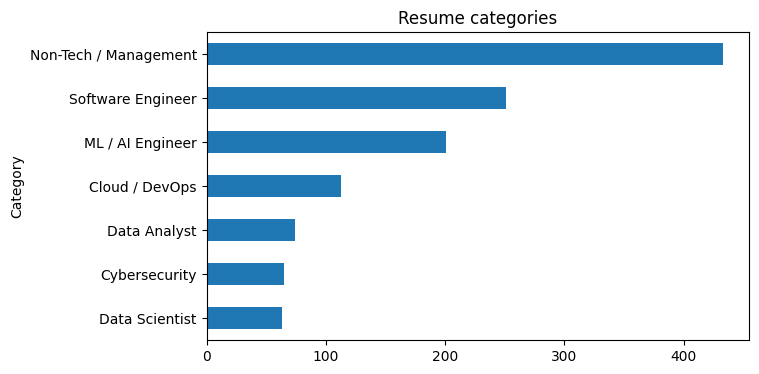

In [ ]:
ROLE_TITLES = sorted(df["Current_Job_Title"].replace("", np.nan).dropna().unique(), key=len, reverse=True)

def extract_role(text):
    t = text.lower()
    for r in ROLE_TITLES:
        if r.lower() in t:
            return r
    if "cybersecurity team as an analyst" in t: return "Cybersecurity Analyst"
    if "nursing role" in t: return "Nurse"
    return "Unknown"

df["Target_Role"] = df["Target_Job_Description"].apply(extract_role)

CATEGORY_MAP = {
    "Machine Learning Engineer": "ML / AI Engineer", "AI Engineer": "ML / AI Engineer",
    "MLOps Specialist": "ML / AI Engineer", "Prompt Engineer": "ML / AI Engineer",
    "AI Ethics Officer": "ML / AI Engineer", "Quantum Computing Specialist": "ML / AI Engineer",
    "Data Scientist": "Data Scientist", "Big Data Engineer": "Data Scientist",
    "Business Analyst": "Data Analyst", "Market Research Analyst": "Data Analyst", "Financial Analyst": "Data Analyst",
    "Software Developer": "Software Engineer", "Software Engineer": "Software Engineer",
    "Full-Stack Developer": "Software Engineer", "Frontend Developer": "Software Engineer",
    "Backend Developer": "Software Engineer", "Mobile Applications Developer": "Software Engineer",
    "Blockchain Engineer": "Software Engineer", "UI/UX Designer": "Software Engineer",
    "Cloud Architect": "Cloud / DevOps", "Cloud Engineer": "Cloud / DevOps",
    "DevOps Engineer": "Cloud / DevOps", "Site Reliability Engineer": "Cloud / DevOps",
    "Cybersecurity Engineer": "Cybersecurity", "Cybersecurity Analyst": "Cybersecurity",
}
df["Category"] = df["Target_Role"].map(CATEGORY_MAP).fillna("Non-Tech / Management")

df["Category"].value_counts().sort_values().plot.barh(title="Resume categories", figsize=(7, 4))
plt.show()

In [ ]:
EDU = {"High School": 0, "Certificate": 1, "Diploma": 2, "Bachelor's": 3, "Master's": 4, "PhD": 5}
df["edu_rank"] = df["Education_Level"].map(EDU)
df["n_skills"] = df["skills_list"].str.len()

df["resume_text"] = (df["Skills"] + ". " + df["Field_of_Study"] + ". " + df["Degrees"] + ". "
                     + df["Certifications"] + ". " + df["Current_Job_Title"] + ". "
                     + df["Previous_Job_Titles"]).str.replace(r"\s+", " ", regex=True)

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(ngram_range=(1, 2), stop_words="english", sublinear_tf=True)
X_tfidf = tfidf.fit_transform(df["resume_text"])
print(X_tfidf.shape)

(1200, 4158)


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    df["resume_text"], df["Category"], test_size=0.2, stratify=df["Category"], random_state=42)

def make(clf):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), stop_words="english", sublinear_tf=True)),("clf", clf)])

models = {
    "Logistic Regression":make(LogisticRegression(max_iter=2000, class_weight="balanced", C=5)),
    "Random Forest":make(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
    "SVM (Linear)":make(LinearSVC(class_weight="balanced")),
}

skf = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, pipe.predict(X_test))
    cv_acc = cross_val_score(pipe, df["resume_text"], df["Category"], cv=skf).mean()
    rows.append((name, test_acc, cv_acc))

results = pd.DataFrame(rows, columns=["Model", "Test Acc", "5-fold CV Acc"]).round(3)
results

,Model,Test Acc,5-fold CV Acc
0,Logistic Regression,0.592,0.592
1,Random Forest,0.588,0.614
2,SVM (Linear),0.604,0.610


Best: Random Forest


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                       precision    recall  f1-score   support

       Cloud / DevOps       0.23      0.13      0.17        23
        Cybersecurity       0.50      0.08      0.13        13
         Data Analyst       0.00      0.00      0.00        15
       Data Scientist       0.71      0.42      0.53        12
     ML / AI Engineer       0.46      0.33      0.38        40
Non-Tech / Management       0.85      0.97      0.90        87
    Software Engineer       0.38      0.70      0.50        50

             accuracy                           0.59       240
            macro avg       0.45      0.37      0.37       240
         weighted avg       0.55      0.59      0.54       240



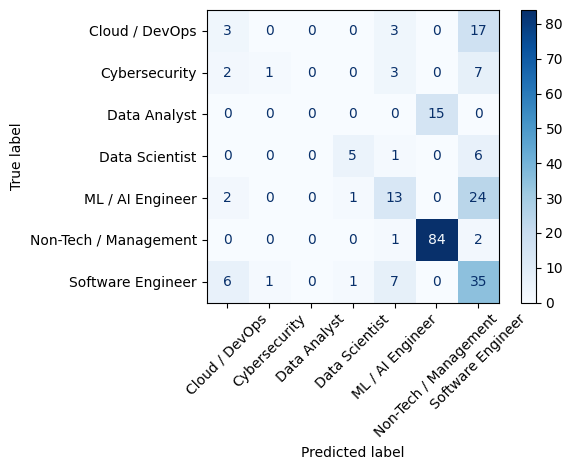

['category_model.joblib']

In [ ]:
best_name = results.sort_values("5-fold CV Acc").iloc[-1]["Model"]
best = models[best_name]
print("Best:", best_name)
print(classification_report(y_test, best.predict(X_test)))
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, xticks_rotation=45, cmap="Blues")
plt.tight_layout(); plt.show()

import joblib
joblib.dump(best, "category_model.joblib")

In [ ]:
import json
EXTRA = ["MLOps", "Airflow", "scikit-learn", "Pandas", "NumPy", "Hugging Face", "Power BI", "Tableau",
         "GCP", "Flask", "FastAPI", "Redis", "PostgreSQL", "MySQL", "C++", "Prometheus", "Grafana",
         "LLMs", "Transformers", "BERT"]
skill_vocab = sorted(set(all_skills.unique()) | set(EXTRA))
json.dump(skill_vocab, open("skills.json", "w"))

In [ ]:
%%writefile resume_utils.py
import json, re
import numpy as np
from sentence_transformers import SentenceTransformer, util

SKILL_VOCAB = json.load(open("skills.json"))
ALIASES = {"k8s": "Kubernetes", "ml": "Machine Learning", "gcp": "Google Cloud",
           "amazon web services": "AWS", "postgres": "PostgreSQL", "sklearn": "scikit-learn"}
CERT_HINTS = {"AWS": "AWS Certified Solutions Architect", "Kubernetes": "Certified Kubernetes Administrator",
              "TensorFlow": "TensorFlow Developer Certificate", "Project Management": "Project Management Professional",
              "Network Security": "CompTIA Security+"}

embedder = SentenceTransformer("all-MiniLM-L6-v2")

def _find(term, text):
    return re.search(r"(?<![a-z0-9+#.])" + re.escape(term.lower()) + r"(?![a-z0-9+#])", text) is not None

def extract_skills(text):
    t = text.lower()
    found = {s for s in SKILL_VOCAB if _find(s, t)}
    found |= {canon for alias, canon in ALIASES.items() if _find(alias, t)}
    return found

def semantic_similarity(resume_text, jd_text):
    emb = embedder.encode([resume_text, jd_text], convert_to_tensor=True, normalize_embeddings=True)
    return util.cos_sim(emb[0], emb[1]).item()

def match_score(resume_text, jd_text, w_sem=0.5, lo=0.15, hi=0.75):
    """Blend of semantic similarity (rescaled to 0-1) and skill coverage."""
    sem = semantic_similarity(resume_text, jd_text)
    sem_scaled = float(np.clip((sem - lo) / (hi - lo), 0, 1))
    jd_sk, res_sk = extract_skills(jd_text), extract_skills(resume_text)
    if jd_sk:
        coverage = len(jd_sk & res_sk) / len(jd_sk)
        score = w_sem * sem_scaled + (1 - w_sem) * coverage
    else:
        score = sem_scaled
    return round(100 * score), sorted(jd_sk - res_sk), sem

def suggest_improvements(resume_text, missing, score):
    tips = []
    for s in missing[:5]:
        tips.append(f"Add {s} to your skills section and back it with a project or bullet that shows it in use.")
    for s in missing:
        if s in CERT_HINTS:
            tips.append(f"Consider a certification such as {CERT_HINTS[s]}.")
            break
    if not re.search(r"\d+%|\$\d|\d+\+?\s*(users|clients|projects|models|systems)", resume_text.lower()):
        tips.append("Quantify your impact (e.g., 'cut inference latency by 30%') instead of listing duties.")
    if len(resume_text.split()) < 150:
        tips.append("Your resume looks short; add project or experience detail relevant to the role.")
    if score < 50:
        tips.append("Mirror the job description's wording in your summary and headline for this role.")
    return tips or ["Strong match: tailor your summary line to this specific role and you're set."]

Overwriting resume_utils.py


In [ ]:
from resume_utils import *

jd = """ML Engineer needed: Python, PyTorch, Docker, AWS, Kubernetes, MLOps, CI/CD.
Experience deploying models to production."""
resume = df.loc[df["Category"] == "ML / AI Engineer", "resume_text"].iloc[0]

score, missing, sem = match_score(resume, jd)
print(f"Match Score: {score}%   (raw cosine: {sem:.2f})")
print("Missing skills:", missing)
print("Category:", best.predict([resume])[0])
for tip in suggest_improvements(resume, missing, score):
    print("-", tip)

Match Score: 32%   (raw cosine: 0.46)
Missing skills: ['AWS', 'CI/CD', 'Docker', 'Kubernetes', 'MLOps', 'PyTorch', 'Python']
Category: ML / AI Engineer
- Add AWS to your skills section and back it with a project or bullet that shows it in use.
- Add CI/CD to your skills section and back it with a project or bullet that shows it in use.
- Add Docker to your skills section and back it with a project or bullet that shows it in use.
- Add Kubernetes to your skills section and back it with a project or bullet that shows it in use.
- Add MLOps to your skills section and back it with a project or bullet that shows it in use.
- Consider a certification such as AWS Certified Solutions Architect.
- Quantify your impact (e.g., 'cut inference latency by 30%') instead of listing duties.
- Your resume looks short; add project or experience detail relevant to the role.
- Mirror the job description's wording in your summary and headline for this role.


In [ ]:
sample = df.sample(200, random_state=1)
r_emb  = embedder.encode(sample["resume_text"].tolist(), convert_to_tensor=True, normalize_embeddings=True)
jd_emb = embedder.encode(sample["Target_Job_Description"].tolist(), convert_to_tensor=True, normalize_embeddings=True)
own      = util.cos_sim(r_emb, jd_emb).diag()
shuffled = util.cos_sim(r_emb, jd_emb.roll(1, dims=0)).diag()
print(f"own JD: {own.mean():.3f}   other JD: {shuffled.mean():.3f}")

own JD: 0.417   other JD: 0.304


In [ ]:
corpus_emb = embedder.encode(df["resume_text"].tolist(), convert_to_tensor=True,
                             normalize_embeddings=True, show_progress_bar=True)
q = embedder.encode(jd, convert_to_tensor=True, normalize_embeddings=True)
for h in util.semantic_search(q, corpus_emb, top_k=5)[0]:
    r = df.iloc[h["corpus_id"]]
    print(f'{h["score"]:.2f}  {r["Name"]:<20} {r["Category"]:<22} {r["Skills"]}')

Batches:   0%|          | 0/38 [00:00<?, ?it/s]

0.70  Noah Smith           Cloud / DevOps         Docker, Kubernetes, Penetration Testing, Python, Linux
0.65  Ava Taylor           Software Engineer      CI/CD, Deep Learning, Docker, Statistics, TensorFlow, Microservices, Computer Vision, Kubernetes
0.65  Olivia Williams      Software Engineer      Data Analysis, Docker, Kubernetes, AWS
0.65  Isabella Garcia      Cloud / DevOps         Ansible, Jenkins, PyTorch, GraphQL, TensorFlow, DevOps, REST APIs, Microservices
0.65  Akash Rao            Software Engineer      Git, TensorFlow, AWS, CI/CD, JavaScript, PyTorch, SQL, Solidity


In [ ]:
%%writefile app.py
import streamlit as st, joblib, pdfplumber
from resume_utils import match_score, suggest_improvements

st.set_page_config(page_title="AI Resume Screener", page_icon="📄")
st.title("AI Resume Screening & Job Matching")

@st.cache_resource
def load_classifier():
    return joblib.load("category_model.joblib")
clf = load_classifier()

pdf_file = st.file_uploader("Upload Resume PDF", type="pdf")
jd_text = st.text_area("Paste Job Description", height=200)

if st.button("Analyze") and pdf_file and jd_text.strip():
    with pdfplumber.open(pdf_file) as pdf:
        resume_text = "\n".join(page.extract_text() or "" for page in pdf.pages)
    if not resume_text.strip():
        st.error("No text found in this PDF (is it a scanned image?).")
        st.stop()

    with st.spinner("Analyzing..."):
        score, missing, sem = match_score(resume_text, jd_text)
        category = clf.predict([resume_text])[0]

    st.metric("Match Score", f"{score}%")
    st.progress(score / 100)
    st.subheader("Predicted Resume Category")
    st.write(category)

    st.subheader("Missing Skills")
    if missing:
        for s in missing:
            st.write(f"- {s}")
    else:
        st.success("No missing skills detected.")

    st.subheader("Suggested Improvements")
    for tip in suggest_improvements(resume_text, missing, score):
        st.write(f"- {tip}")

Overwriting app.py


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!nohup streamlit run app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false > streamlit.log 2>&1 &
!nohup ./cloudflared tunnel --url http://localhost:8501 > tunnel.log 2>&1 &
import time; time.sleep(8)
!grep -o 'https://[-a-z0-9]*\.trycloudflare\.com' tunnel.log | head -1

https://advisors-fixes-advised-solely.trycloudflare.com
